# Лабораторная работа № 8

## Бинарная классификация с использованием нейросети

**Вариант 14 – Сотрудники компании.** Датасет – `employees_4.csv` (набор данных лабораторной работы № 4, бинарная классификация).

Цель работы – изучить архитектуру и принцип работы нейронных сетей на примере решения задачи бинарной классификации: по данным о сотруднике предсказать, уйдёт ли он из компании (`LeaveOrNot`: 1 – ушёл, 0 – остался).

## 1. Импорт необходимых библиотек

In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, callbacks
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Для воспроизводимости результатов
keras.utils.set_random_seed(42)

## 2. Загрузка и первичный анализ данных

In [2]:
# Загружаем набор данных как датафрейм pandas
df = pd.read_csv('employees_4.csv')
df.head()

,Education,JoiningYear,City,PaymentTier,Age,Gender,EverBenched,ExperienceInCurrentDomain,LeaveOrNot
0,Bachelors,2017,Bangalore,3,34,Male,No,0,0
1,Bachelors,2013,Pune,1,28,Female,No,3,1
2,Bachelors,2014,New Delhi,3,38,Female,No,2,0
3,Masters,2016,Bangalore,3,27,Male,No,5,1
4,Masters,2017,Pune,3,24,Male,Yes,2,1


In [3]:
print("Размерность датафрейма:", df.shape)

Размерность датафрейма: (4653, 9)


In [4]:
df.describe()

,JoiningYear,PaymentTier,Age,ExperienceInCurrentDomain,LeaveOrNot
count,4653.000000,4653.000000,4653.000000,4653.000000,4653.000000
mean,2015.062970,2.698259,29.393295,2.905652,0.343864
std,1.863377,0.561435,4.826087,1.558240,0.475047
min,2012.000000,1.000000,22.000000,0.000000,0.000000
25%,2013.000000,3.000000,26.000000,2.000000,0.000000
50%,2015.000000,3.000000,28.000000,3.000000,0.000000
75%,2017.000000,3.000000,32.000000,4.000000,1.000000
max,2018.000000,3.000000,41.000000,7.000000,1.000000


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4653 entries, 0 to 4652
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   Education                  4653 non-null   object
 1   JoiningYear                4653 non-null   int64 
 2   City                       4653 non-null   object
 3   PaymentTier                4653 non-null   int64 
 4   Age                        4653 non-null   int64 
 5   Gender                     4653 non-null   object
 6   EverBenched                4653 non-null   object
 7   ExperienceInCurrentDomain  4653 non-null   int64 
 8   LeaveOrNot                 4653 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 327.3+ KB


## 3. Предобработка данных

### 3.1. Обработка пропусков

In [6]:
# Проверяем наличие пропусков (NaN)
print(df.isna().sum())
print("\nВсего пропусков:", df.isna().sum().sum())

Education                    0
JoiningYear                  0
City                         0
PaymentTier                  0
Age                          0
Gender                       0
EverBenched                  0
ExperienceInCurrentDomain    0
LeaveOrNot                   0
dtype: int64

Всего пропусков: 0


Пропущенных значений в данных нет, поэтому заполнение или удаление строк не требуется.

### 3.2. Кодирование категориальных признаков в дискретные величины

In [7]:
X = df.drop(columns=['LeaveOrNot']).copy()
y = df['LeaveOrNot'].copy()

# Education (есть естественный порядок), Gender и EverBenched (два значения) - кодируем целыми числами
ord_cols = ['Education', 'Gender', 'EverBenched']
ord_encoder = OrdinalEncoder(categories=[['Bachelors', 'Masters', 'PHD'], ['Female', 'Male'], ['No', 'Yes']])
X[ord_cols] = ord_encoder.fit_transform(X[ord_cols])

# City не имеет порядка - кодируем бинарными признаками (one-hot)
ohe = OneHotEncoder(drop='first', sparse_output=False)
city_dummies = pd.DataFrame(ohe.fit_transform(X[['City']]),
                            columns=ohe.get_feature_names_out(['City']), index=X.index)
X = pd.concat([X.drop(columns=['City']), city_dummies], axis=1)

print("Количество признаков:", X.shape[1])
X.head()

Количество признаков: 9


,Education,JoiningYear,PaymentTier,Age,Gender,EverBenched,ExperienceInCurrentDomain,City_New Delhi,City_Pune
0,0.0,2017,3,34,1.0,0.0,0,0.0,0.0
1,0.0,2013,1,28,0.0,0.0,3,0.0,1.0
2,0.0,2014,3,38,0.0,0.0,2,1.0,0.0
3,1.0,2016,3,27,1.0,0.0,5,0.0,0.0
4,1.0,2017,3,24,1.0,1.0,2,0.0,1.0


Пояснения:
- `OrdinalEncoder` превращает категории `Education`, `Gender`, `EverBenched` в целые числа;
- `OneHotEncoder` превращает `City` в бинарные признаки (с `drop='first'` одна категория отбрасывается, чтобы избежать мультиколлинеарности), так как у городов нет порядка.

## 4. Разделение данных на обучающую и тестовую выборки

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Обучающая выборка: {X_train.shape[0]} samples")
print(f"Тестовая выборка: {X_test.shape[0]} samples")

Обучающая выборка: 3722 samples
Тестовая выборка: 931 samples


## 5. Масштабирование признаков

Нейронные сети лучше работают (градиентный спуск быстрее сходится), когда числовые признаки имеют сопоставимый масштаб. Масштабируем числовые признаки; параметры масштабирования считаем только по обучающей выборке.

In [9]:
num_cols = ['JoiningYear', 'PaymentTier', 'Age', 'ExperienceInCurrentDomain']

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

X_train_scaled.head()

,Education,JoiningYear,PaymentTier,Age,Gender,EverBenched,ExperienceInCurrentDomain,City_New Delhi,City_Pune
4097,0.0,-1.660210,0.536275,1.787302,0.0,0.0,-1.230717,1.0,0.0
1694,0.0,1.559295,0.536275,-0.697541,1.0,0.0,0.696658,0.0,0.0
2659,0.0,0.486126,0.536275,-0.490470,1.0,0.0,1.339116,0.0,1.0
3860,0.0,0.486126,0.536275,1.373162,1.0,0.0,0.696658,0.0,0.0
1250,0.0,1.022710,0.536275,-0.490470,1.0,1.0,1.339116,0.0,0.0


In [10]:
# Приводим данные к массивам numpy для нейросети
X_train_arr = X_train_scaled.to_numpy(dtype='float32')
X_test_arr = X_test_scaled.to_numpy(dtype='float32')
y_train_arr = y_train.to_numpy(dtype='float32')
y_test_arr = y_test.to_numpy(dtype='float32')

## 6. Проектирование нейросети

Нейронная сеть – многослойный персептрон (сеть прямого распространения):
- **входной слой** – число нейронов равно числу признаков;
- **скрытые слои** – полносвязные слои `Dense` с функцией активации ReLU или Tanh (число слоёв и нейронов подбирается экспериментально в разделе 9);
- **Dropout** – случайно отключает часть нейронов при обучении и снижает переобучение;
- **выходной слой** – 1 нейрон с функцией активации Sigmoid, выход интерпретируется как вероятность того, что сотрудник уйдёт (класс 1).

Чтобы не переписывать код при каждом эксперименте, оформим создание модели, обучение и оценку в виде функций.

In [11]:
n_features = X_train_arr.shape[1]
print("Количество входных нейронов:", n_features)


def build_model(hidden=(64, 32), activation='relu'):
    """Создаёт (некомпилированную) нейросеть с заданными скрытыми слоями."""
    model = models.Sequential()
    model.add(layers.Input(shape=(n_features,)))
    for i, units in enumerate(hidden):
        model.add(layers.Dense(units, activation=activation))
        model.add(layers.Dropout(0.3 if i == 0 else 0.2))
    model.add(layers.Dense(1, activation='sigmoid'))
    return model


def evaluate_model(model, X, y):
    """Accuracy, Precision, Recall и F1 при пороге вероятности 0.5."""
    y_pred = (model.predict(X, verbose=0) > 0.5).astype(int).ravel()
    return {
        'Accuracy': accuracy_score(y, y_pred),
        'Precision': precision_score(y, y_pred),
        'Recall': recall_score(y, y_pred),
        'F1': f1_score(y, y_pred),
    }


def plot_history(history, title):
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Val Loss')
    plt.xlabel('Epoch')
    plt.legend()
    plt.title(title + ': Loss over epochs')
    plt.subplot(1, 2, 2)
    plt.plot(history.history['accuracy'], label='Train Acc')
    plt.plot(history.history['val_accuracy'], label='Val Acc')
    plt.xlabel('Epoch')
    plt.legend()
    plt.title(title + ': Accuracy over epochs')
    plt.show()

Количество входных нейронов: 9


## 7. Базовая модель: компиляция и обучение

### 7.1. Создание и компиляция модели

In [12]:
model = build_model(hidden=(64, 32), activation='relu')
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 64)                  │             640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,753 (10.75 KB)

 Trainable params: 2,753 (10.75 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy', keras.metrics.Precision(name='precision'), keras.metrics.Recall(name='recall')]
)

Параметры компиляции:
- `optimizer='adam'` – адаптивный метод градиентного спуска;
- `loss='binary_crossentropy'` – стандартная функция потерь для бинарной классификации;
- `metrics` – отслеживаем accuracy, precision и recall.

### 7.2. Обучение с валидацией

Часть обучающей выборки (20 %) отводится под валидацию для контроля переобучения. Ранняя остановка прекращает обучение, если `val_loss` не улучшается 10 эпох подряд, и возвращает лучшие веса.

In [14]:
early_stop = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train_arr, y_train_arr,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    verbose=1,
    callbacks=[early_stop]
)

Epoch 1/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6594 - loss: 0.6339 - precision: 0.5155 - recall: 0.1785 - val_accuracy: 0.7087 - val_loss: 0.5680 - val_precision: 0.6583 - val_recall: 0.3098
Epoch 2/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7078 - loss: 0.5739 - precision: 0.6605 - recall: 0.3112 - val_accuracy: 0.7477 - val_loss: 0.5355 - val_precision: 0.7055 - val_recall: 0.4510
Epoch 3/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7296 - loss: 0.5588 - precision: 0.6815 - recall: 0.4029 - val_accuracy: 0.7772 - val_loss: 0.5141 - val_precision: 0.7514 - val_recall: 0.5216
Epoch 4/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7481 - loss: 0.5395 - precision: 0.7193 - recall: 0.4400 - val_accuracy: 0.7879 - val_loss: 0.4960 - val_precision: 0.7622 - val_recall: 0.5529
Epoch 5/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7659 - loss: 0.5219 - precision: 0.7563 - recall: 0.4722 - val_accuracy: 0.7987 - val_loss: 0.4801 

## 8. Оценка базовой модели

In [15]:
base_train = evaluate_model(model, X_train_arr, y_train_arr)
base_test = evaluate_model(model, X_test_arr, y_test_arr)

print(f"Обучение остановлено на эпохе {len(history.history['loss'])}")
print("Метрики на тестовой выборке (базовая модель):")
for name, value in base_test.items():
    print(f"  {name}: {value:.4f}")

Обучение остановлено на эпохе 100
Метрики на тестовой выборке (базовая модель):
  Accuracy: 0.8346
  Precision: 0.8879
  Recall: 0.5938
  F1: 0.7116


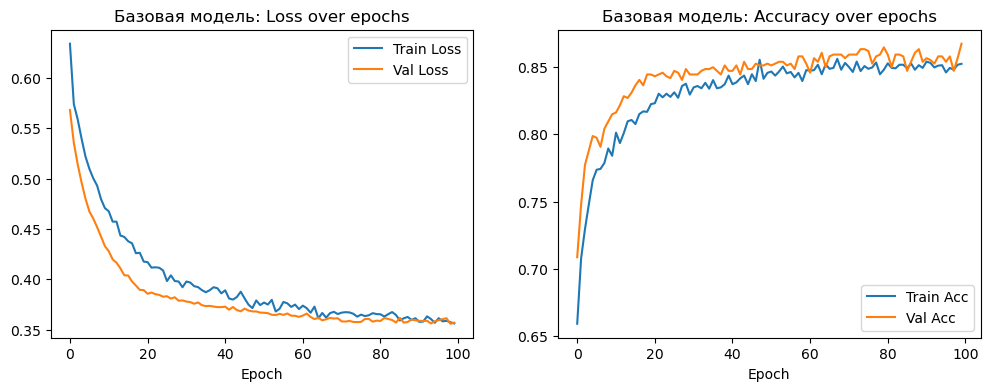

In [16]:
plot_history(history, 'Базовая модель')

График помогает увидеть, не переобучается ли модель (расхождение между train и val).

## 9. Подбор гиперпараметров

Подбор выполняется экспериментально и последовательно: сначала подбирается архитектура сети, затем функция активации, оптимизатор, скорость обучения, размер батча и количество эпох; каждый следующий эксперимент использует лучшее значение, найденное на предыдущих шагах. Качество сравнивается по **валидационной** выборке (минимальное значение `val_loss` при ранней остановке); тестовая выборка в подборе не участвует.

In [17]:
def run_experiment(hidden=(64, 32), activation='relu', optimizer='adam', lr=0.001,
                   batch_size=32, epochs=100, early=True):
    """Обучает модель с заданными гиперпараметрами и возвращает результаты по валидации."""
    keras.backend.clear_session()
    keras.utils.set_random_seed(42)
    m = build_model(hidden, activation)
    opt = keras.optimizers.Adam(learning_rate=lr) if optimizer == 'adam' else keras.optimizers.SGD(learning_rate=lr)
    m.compile(optimizer=opt, loss='binary_crossentropy', metrics=['accuracy'])
    cb = [callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)] if early else []
    h = m.fit(X_train_arr, y_train_arr, validation_split=0.2, epochs=epochs,
              batch_size=batch_size, verbose=0, callbacks=cb)
    best = int(np.argmin(h.history['val_loss']))
    return m, h, {
        'val_loss': h.history['val_loss'][best],
        'val_accuracy': h.history['val_accuracy'][best],
        'best_epoch': best + 1,
        'epochs_trained': len(h.history['loss']),
    }


# Параметры, с которых начинаем (как у базовой модели)
params = {'hidden': (64, 32), 'activation': 'relu', 'optimizer': 'adam', 'lr': 0.001, 'batch_size': 32}


def tune(name, key, values):
    """Перебирает значения одного гиперпараметра, выбирает лучшее по val_loss."""
    rows = []
    for v in values:
        p = dict(params)
        p[key] = v
        _, _, res = run_experiment(**p)
        rows.append({name: str(v), **res})
    table = pd.DataFrame(rows).set_index(name)
    best_value = values[int(table['val_loss'].to_numpy().argmin())]
    params[key] = best_value
    print(f"Лучшее значение: {best_value}")
    return table.round(4)

### 9.1. Количество скрытых слоёв и нейронов

In [18]:
tune('Скрытые слои', 'hidden', [(16,), (32,), (64,), (64, 32), (128, 64), (64, 32, 16)])


Лучшее значение: (64, 32, 16)


,val_loss,val_accuracy,best_epoch,epochs_trained
Скрытые слои,,,,
"(16,)",0.3973,0.8362,100,100
"(32,)",0.3813,0.8483,100,100
"(64,)",0.3708,0.8550,95,100
"(64, 32)",0.3558,0.8564,99,100
"(128, 64)",0.3611,0.8631,40,50
"(64, 32, 16)",0.3516,0.8631,73,83


### 9.2. Функция активации скрытых слоёв (ReLU и Tanh)

In [19]:
tune('Активация', 'activation', ['relu', 'tanh'])

Лучшее значение: relu


,val_loss,val_accuracy,best_epoch,epochs_trained
Активация,,,,
relu,0.3516,0.8631,73,83
tanh,0.3819,0.8510,60,70


### 9.3. Оптимизатор (Adam и SGD)

In [20]:
tune('Оптимизатор', 'optimizer', ['adam', 'sgd'])

Лучшее значение: adam


,val_loss,val_accuracy,best_epoch,epochs_trained
Оптимизатор,,,,
adam,0.3516,0.8631,73,83
sgd,0.5855,0.6832,100,100


### 9.4. Скорость обучения (learning rate)

In [21]:
tune('Learning rate', 'lr', [0.0001, 0.001, 0.01, 0.1])

Лучшее значение: 0.001


,val_loss,val_accuracy,best_epoch,epochs_trained
Learning rate,,,,
0.0001,0.4209,0.8161,100,100
0.001,0.3516,0.8631,73,83
0.01,0.3594,0.8497,18,28
0.1,0.6425,0.6577,4,14


### 9.5. Размер батча (batch size)

In [22]:
tune('Batch size', 'batch_size', [16, 32, 64, 128])

Лучшее значение: 16


,val_loss,val_accuracy,best_epoch,epochs_trained
Batch size,,,,
16,0.3497,0.8644,54,64
32,0.3516,0.8631,73,83
64,0.3522,0.8617,70,80
128,0.3583,0.8550,98,100


### 9.6. Количество эпох

Обучаем модель с лучшими найденными параметрами 150 эпох без ранней остановки и смотрим, на какой эпохе значение `val_loss` минимально: дальше начинается переобучение.

Выбранные гиперпараметры: {'hidden': (64, 32, 16), 'activation': 'relu', 'optimizer': 'adam', 'lr': 0.001, 'batch_size': 16}
Минимальный val_loss = 0.3468 на эпохе 85


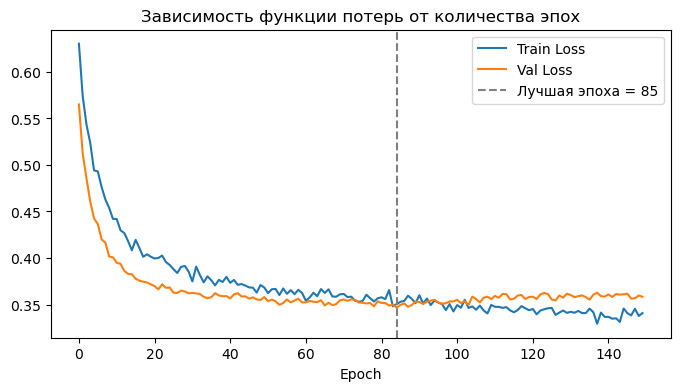

In [23]:
_, h_epochs, res_epochs = run_experiment(**params, epochs=150, early=False)

best_epoch = res_epochs['best_epoch']
print("Выбранные гиперпараметры:", params)
print(f"Минимальный val_loss = {res_epochs['val_loss']:.4f} на эпохе {best_epoch}")

plt.figure(figsize=(8, 4))
plt.plot(h_epochs.history['loss'], label='Train Loss')
plt.plot(h_epochs.history['val_loss'], label='Val Loss')
plt.axvline(best_epoch - 1, color='gray', linestyle='--', label=f'Лучшая эпоха = {best_epoch}')
plt.xlabel('Epoch')
plt.legend()
plt.title('Зависимость функции потерь от количества эпох')
plt.show()

## 10. Итоговая модель с подобранными гиперпараметрами

In [24]:
final_model, final_history, _ = run_experiment(**params, epochs=best_epoch, early=False)
final_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 64)                  │             640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 16)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 9,797 (38.27 KB)

 Trainable params: 3,265 (12.75 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 6,532 (25.52 KB)

In [25]:
final_train = evaluate_model(final_model, X_train_arr, y_train_arr)
final_test = evaluate_model(final_model, X_test_arr, y_test_arr)

print("Метрики на тестовой выборке (итоговая модель):")
for name, value in final_test.items():
    print(f"  {name}: {value:.4f}")

comparison = pd.DataFrame({'Базовая модель': base_test, 'Итоговая модель': final_test}).round(4)
comparison

Метрики на тестовой выборке (итоговая модель):
  Accuracy: 0.8421
  Precision: 0.8879
  Recall: 0.6188
  F1: 0.7293


,Базовая модель,Итоговая модель
Accuracy,0.8346,0.8421
Precision,0.8879,0.8879
Recall,0.5938,0.6188
F1,0.7116,0.7293


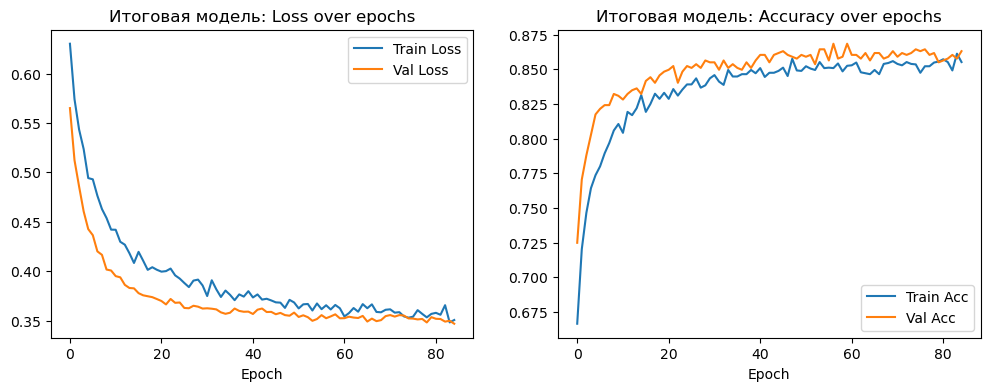

In [26]:
plot_history(final_history, 'Итоговая модель')

## 11. Заключение

In [27]:
print("Подобранные гиперпараметры:", params, "эпох:", best_epoch)
print(f"Train Accuracy = {final_train['Accuracy']:.4f}, Test Accuracy = {final_test['Accuracy']:.4f}")
print(f"Precision = {final_test['Precision']:.4f}, Recall = {final_test['Recall']:.4f}, F1 = {final_test['F1']:.4f}")

Подобранные гиперпараметры: {'hidden': (64, 32, 16), 'activation': 'relu', 'optimizer': 'adam', 'lr': 0.001, 'batch_size': 16} эпох: 85
Train Accuracy = 0.8694, Test Accuracy = 0.8421
Precision = 0.8879, Recall = 0.6188, F1 = 0.7293


Лабораторная работа показала, что многослойный персептрон решает задачу предсказания ухода сотрудника с приемлемым, но не очень высоким качеством.

**Что сделано.** Данные закодированы (`OrdinalEncoder`, `OneHotEncoder`) и масштабированы (`StandardScaler`), разделены на обучающую (80 %) и тестовую (20 %) выборки. Базовая сеть: 9 входных нейронов, скрытые слои 64 и 32 нейрона (ReLU) с Dropout, выходной нейрон с Sigmoid; оптимизатор Adam, функция потерь binary crossentropy, 20 % обучающей выборки отведено под валидацию.

**Подбор гиперпараметров** (по `val_loss` на валидационной выборке, тест в подборе не участвовал):
- архитектура: лучший результат у сети с тремя скрытыми слоями (64, 32, 16): `val_loss` 0.352 против 0.397 у сети с одним слоем из 16 нейронов;
- функция активации: ReLU (0.352) лучше Tanh (0.382);
- оптимизатор: Adam (0.352) значительно лучше SGD (0.586), SGD при той же скорости обучения сходится очень медленно;
- скорость обучения: оптимальна 0.001; при 0.0001 сеть не успевает обучиться за 100 эпох (0.421), при 0.1 обучение неустойчиво (0.643);
- размер батча почти не влияет на результат (`val_loss` от 0.350 до 0.358), выбран 16;
- число эпох: `val_loss` минимален на 85-й эпохе, после неё перестаёт снижаться, тогда как ошибка на обучающей выборке продолжает уменьшаться, то есть дальше начинается переобучение. Итоговая модель обучалась 85 эпох.

**Результаты на тестовой выборке:**

| Метрика | Базовая модель | Итоговая модель |
|---|---|---|
| Accuracy | 0.8346 | 0.8421 |
| Precision | 0.8879 | 0.8879 |
| Recall | 0.5938 | 0.6188 |
| F1 | 0.7116 | 0.7293 |

Подбор гиперпараметров улучшил модель, но незначительно: accuracy выросла примерно на 0.8 п.п., F1 – на 1.8 п.п.

**Переобучения нет:** на графиках кривые потерь и точности на обучающей и валидационной выборках идут близко (точность на train 0.869, на тесте 0.842), а небольшое превышение валидационной точности над обучающей объясняется тем, что при обучении работает Dropout.

**Пригодность модели.** Модель правильно классифицирует около 84 % сотрудников, а если она предсказывает уход, то в 89 % случаев не ошибается (precision). Однако полнота невысока (0.62): модель пропускает примерно 38 % сотрудников, которые действительно уходят; классы не сбалансированы (ушли около 34 %). Поэтому модель пригодна для предварительной оценки группы риска, но не для надёжного предсказания ухода каждого отдельного сотрудника. Для повышения полноты можно уменьшить порог классификации, использовать веса классов или добавить новые признаки.